# Food and body-image themes in annotated social media posts
**INFO 2950 · Phase II · Parts 1 and 2**  
**Group:** Anya Choudhary; Zara Islam (zsi2); Riya Gupta (rg823); April Vorontsova (vv252).

Github repo: AnyaChoudhary/info2950-fall2026-project

## 1. Research questions
Our main question is: What food and body-image concerns appear in these posts, and how do they relate to other features of the posts?

1. Which concerns and content features appear in each dataset, and how common are they among posts where each label applies?
2. Among Twitter posts about eating disorders or body image, are shape-concern and eating-concern labels associated?
3. In EDTT, is a restraint label associated with audio valence after accounting for whether the post is a video or photo slideshow?

Phase II explores question 1. Questions 2 and 3 are planned for the final report and have not been tested. The files describe posts, so they cannot show algorithm effects, engagement effects, diagnoses, or changes in a person's relationship with food. Recovery and social comparison are not measured consistently enough to use as shared outcomes.

Twitter provides a larger sample of coded posts; EDTT provides a smaller sample with visual and audio features. We analyze them separately because their collection methods and labels differ.

### Questions and data
| Question | Dataset | What we measure | Possible predictors | Posts included |
|---|---|---|---|---|
| 1 | Twitter and EDTT, separately | Counts and percentages for each label | None; descriptive summaries | Depends on the label's coding rules |
| 2 | Twitter | Eating concern (`eating`) | Shape concern (`shape`) | 2,584 related posts |
| 3 | EDTT | Audio valence (`audio_valence`, 0 to 1) | Restraint (`ede_restraint`) and post format (`type`) | 79 posts with nonblank EDE text |

All measures come from released fields or labels extracted directly from them. For question 3, the planned model will code `type` as photos versus video; a separate `photos` column has not been added to the cleaned data. None of these questions requires viewer, engagement, or exposure data.

## 2. Data collection and cleaning
### 2.1 Data sources
The source files were downloaded on October 15, 2026. Downloads occurred outside the notebook, as the rubric requests collection descriptions but no collection code. Original bytes are retained under data/raw/; the manifest records URLs and SHA-256 checksums. The same unchanged files are hosted in the [project GitHub raw-data folder](https://github.com/AnyaChoudhary/info2950-fall2026-project/tree/905e574351e821300dc5b199747216a3bd630e1b/data/raw), pinned to the verified upload commit so reviewers can retrieve the exact inputs.

Twitter: Cavazos-Rehg et al. (2019), [PLOS ONE article](https://doi.org/10.1371/journal.pone.0207506), [S1 Dataset](https://journals.plos.org/plosone/article/file?id=10.1371/journal.pone.0207506.s002&type=supplementary), and [S1 Codebook](https://journals.plos.org/plosone/article/file?id=10.1371/journal.pone.0207506.s003&type=supplementary). The study sampled 3,000 English-language posts from a keyword-selected January 2015 corpus. The release supplies de-identified codes. The original post text is not included. The published methods describe trained coders and adjudication.

TikTok: Shaveet, Viranda, and Choudhury (2026), [EDTT v2](https://doi.org/10.5281/zenodo.19749827), [public CSV](https://zenodo.org/records/19749827/files/EDTT_public.csv?download=1), and [data dictionary](https://edenshaveet.github.io/EDTT/). This is a curated, expert-annotated pro-ED content sample assembled through text retrieval and recommendation surfacing. Private post identifiers and transcripts are withheld. The record was published in April 2026; the proposed 2024–2025 collection window was not verified in the public documentation inspected and is not assumed here.

Project files, cleaning outputs, and documentation are available in the [GitHub repository](https://github.com/AnyaChoudhary/info2950-fall2026-project).

No scraping, individual contact, account identification, or new annotation was performed. No API credentials were required.

### 2.2 Setup
Run this notebook with the included data/ directory. It locates the project root automatically when opened from the repository's notebooks/ folder or the extracted bundle. In Colab, if the files are absent, the next cell restores the exact saved inputs from the pinned GitHub snapshot. It then checks file integrity and configures consistent figures. This restores existing project files; the original data collection from publishers occurred separately. A changed raw file fails explicitly rather than silently changing the results.

#### Imports
Load the libraries once at the beginning. Pandas handles the tables; matplotlib handles the charts. The file and checksum tools let the same notebook run locally or in Colab.

In [1]:
# Import the libraries used below.
from pathlib import Path
import hashlib, json, re, sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from urllib.request import urlopen
import ssl
import certifi
from matplotlib import font_manager

# Show complete definitions in notebook tables.
pd.set_option('display.max_colwidth', None)

#### Find the data
Use the supplied data folder when it is available. Otherwise, restore the saved project inputs from GitHub and check their hashes. This setup restores the existing files; it does not collect new posts.

In [2]:
# Find the project folder and restore missing inputs.
tls_context = ssl.create_default_context(cafile=certifi.where())
candidates = [Path.cwd(), Path.cwd() / 'info2950_project', *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'data/raw/manifest.json').exists()), None)
if ROOT is None:
    ROOT = Path.cwd() / 'info2950_project'
    raw_folder = ROOT / 'data/raw'
    raw_folder.mkdir(parents=True, exist_ok=True)
    commit = '905e574351e821300dc5b199747216a3bd630e1b'
    base = ('https://raw.githubusercontent.com/AnyaChoudhary/'
            f'info2950-fall2026-project/{commit}/data/raw/')
    try:
        with urlopen(base + 'manifest.json', timeout=45, context=tls_context) as response:
            manifest_bytes = response.read()
        manifest_hash = '05debbe74cce74f95992e9eccc3c333843031b3bcc65f50ccae8292e04be163c'
        assert hashlib.sha256(manifest_bytes).hexdigest() == manifest_hash
        saved_inputs = json.loads(manifest_bytes)
        for item in saved_inputs:
            name = item['file']
            assert Path(name).name == name, 'Unexpected input filename.'
            with urlopen(base + name, timeout=45, context=tls_context) as response:
                contents = response.read()
            assert hashlib.sha256(contents).hexdigest() == item['sha256'], name
            (raw_folder / name).write_bytes(contents)
        # Write the manifest last so an interrupted restore can be retried.
        (raw_folder / 'manifest.json').write_bytes(manifest_bytes)
    except Exception as exc:
        raise RuntimeError(
            'Could not restore the saved inputs. Check the internet connection '
            'and rerun, or extract the full project bundle before running.'
        ) from exc
    print('Restored the four verified source files from the saved GitHub snapshot.')
RAW = ROOT / 'data/raw'
INTER = ROOT / 'data/intermediate'
CLEAN = ROOT / 'data/processed'
FIG = ROOT / 'figures'
for folder in [INTER, CLEAN, FIG]:
    folder.mkdir(parents=True, exist_ok=True)

#### Check the files
Compare each raw file with its saved checksum before cleaning. A mismatch stops the notebook so changed input files cannot silently change the results.

In [3]:
# Verify all raw files.
manifest = json.loads((RAW / 'manifest.json').read_text())
for item in manifest:
    actual = hashlib.sha256((RAW / item['file']).read_bytes()).hexdigest()
    assert actual == item['sha256'], item['file']
assert hashlib.md5((RAW / 'EDTT_public.csv').read_bytes()).hexdigest() == '8bf6f87fd0ff4147790209f66ee364ea'

print('All four source files passed the checksum checks.')

All four source files passed the checksum checks.


#### Chart settings
Set the font and colors used by the existing charts. The helper saves each chart before displaying it.

In [4]:
# Prefer Times New Roman; keep a portable serif fallback for other computers.
font_folder = Path('/System/Library/Fonts/Supplemental')
for font_file in font_folder.glob('Times New Roman*.ttf'):
    font_manager.fontManager.addfont(str(font_file))
plt.rcParams.update({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
                     'text.color': 'black', 'axes.labelcolor': 'black',
                     'axes.titlecolor': 'black', 'xtick.color': 'black',
                     'ytick.color': 'black', 'figure.dpi': 130, 'savefig.dpi': 180,
                     'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
BLUE, TEAL, ORANGE = '#315B86', '#16847D', '#C87A36'
def finish(name):
    plt.savefig(FIG / (name + '.png'), bbox_inches='tight')
    plt.show()
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'numpy {np.__version__} | matplotlib {matplotlib.__version__}')

Python 3.12.0 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2


### 2.3 Clean Twitter data
`shape` is a content label for concern about body shape or appearance, such as a focus on thinness or specific body areas. It is different from a table's `.shape`, which reports its number of rows and columns. The content label does not diagnose a person.

We keep all original columns so each result can be traced to the source. The cleaned analysis file includes only posts coded as related to eating disorders or body image (`ed_about = 1`). The intermediate file keeps all 3,000 source rows.

#### Read and check codes
Read the CSV, standardize column names, and check IDs and allowed values. Nullable integers preserve blanks. Most annotation codes are 0 or 1; `ed_about` also allows 9 for unknown, and `id` is a row identifier.

In [5]:
# CSV import: Lecture 2.
# Validate every Twitter code and its conditional eligibility before filtering.
tw_raw = pd.read_csv(RAW / 'twitter_s1.csv')
tw = tw_raw.copy()
tw.columns = tw.columns.str.strip().str.lower()
assert tw['id'].notna().all() and tw['id'].is_unique
for col in tw:
    tw[col] = pd.to_numeric(tw[col], errors='raise').astype('Int64')
    if col != 'id':
        allowed = {0, 1, 9} if col == 'ed_about' else {0, 1}
        assert set(tw[col].dropna()).issubset(allowed), col

#### Check when each label applies
Image labels apply to shape-concern posts; body-image details apply only when those posts have an image. Restraint and binge/purge labels apply only to eating-concern posts. Aversion follows the source's `noconcern` rule.

The checks below confirm that labels are present where required and blank where the codebook skips them. These skipped entries stay blank instead of becoming zeros.

In [6]:
# Check the codebook skip rules.
eligible = {'ed_about': pd.Series(True, index=tw.index)}
for col in ['shape', 'eating', 'weight', 'noconcern']:
    eligible[col] = (tw['ed_about'] == 1)
eligible['noimage'] = (tw['shape'] == 1).fillna(False)
for col in ['body', 'thighs', 'stomach', 'hipbones', 'ribs', 'collarbones', 'extreme']:
    eligible[col] = ((tw['shape'] == 1) & (tw['noimage'] == 0)).fillna(False)
for col in ['restraint', 'purge']:
    eligible[col] = (tw['eating'] == 1).fillna(False)
eligible['aversion'] = (tw['noconcern'] == 1).fillna(False)
audit = []
for col, mask in eligible.items():
    inside_missing = int(tw.loc[mask, col].isna().sum())
    outside_recorded = int(tw.loc[~mask, col].notna().sum())
    assert inside_missing == 0 and outside_recorded == 0, col
    audit.append([col, int(mask.sum()), int((~mask).sum()), inside_missing])
twitter_audit = pd.DataFrame(audit, columns=[
    'field', 'eligible n', 'outside universe n', 'unexpected missing n'])
display(twitter_audit)

,field,eligible n,outside universe n,unexpected missing n
0,ed_about,3000,0,0
1,shape,2584,416,0
2,eating,2584,416,0
3,weight,2584,416,0
4,noconcern,2584,416,0
5,noimage,1679,1321,0
6,body,861,2139,0
7,thighs,861,2139,0
8,stomach,861,2139,0
9,hipbones,861,2139,0


#### Keep related posts and flag conflicts
Keep `ed_about = 1` rows for analysis. Eleven source rows say `noconcern = 0` even though shape, eating, and weight are all zero. We flag them and preserve their original labels because the released data cannot tell us which label is wrong. Repeated code patterns are not removed: different posts can share the same labels.

In [7]:
# Save the full validated table and the related-post subset.
tw.to_csv(INTER / 'twitter_validated.csv', index=False)
twitter = tw.loc[(tw['ed_about'] == 1)].copy()
# Audit a logical inconsistency without overwriting any original annotation.
expected_none = (twitter[['shape', 'eating', 'weight']] == 0).all(axis=1).astype(int)
logic_mismatch = (twitter['noconcern'] != expected_none)
twitter['noconcern_inconsistent'] = logic_mismatch.astype('Int64')
twitter.loc[logic_mismatch, ['id', 'noconcern_inconsistent']].to_csv(
    CLEAN / 'twitter_logic_flags.csv', index=False)
print('Rows with inconsistent noconcern code:', int(logic_mismatch.sum()))
twitter.to_csv(CLEAN / 'twitter_related.csv', index=False)
display(tw['ed_about'].value_counts().rename_axis('ed_about').to_frame('n'))
print('Unique IDs:', tw.id.nunique(), '| Full-row duplicates:', tw.duplicated().sum())
print('Retained related posts:', len(twitter), '| Excluded unrelated/unknown:', len(tw)-len(twitter))

Rows with inconsistent noconcern code: 11


,n
ed_about,
1,2584
0,342
9,74


Unique IDs: 3000 | Full-row duplicates: 0
Retained related posts: 2584 | Excluded unrelated/unknown: 416


### 2.4 Clean TikTok data
The public EDTT CSV has no post ID. We assign `record_id` from the original row order solely to track this file. We check exact duplicates but do not infer duplicate posts from similar summaries or shared audio.

We standardize column names, trim surrounding whitespace, preserve annotation wording, validate numeric ranges and post format, and derive indicators from explicit category headers. Header matching is case-insensitive and allows a header after either a semicolon or a colon; this accommodates an observed separator inconsistency in the visual annotations. We do not silently fix item-level spelling errors or reinterpret free text.

A blank EDE subscale field remains unknown for all four derived EDE indicators; it is not recoded to four zeros. A zero on a nonblank field means the category was not recorded there, not that a clinical symptom is absent. Blank diagnostic fields are also preserved; their meaning is not resolved by the inspected dictionary. Numeric audio labels are checked against the dictionary's thresholds, and disagreements are reported rather than overwritten.

#### Read and tidy the columns
Keep all 13 source fields, trim surrounding spaces, and use consistent column names. Add a row number to trace each record; it is not a TikTok post ID.

In [8]:
# Normalize the EDTT schema while retaining raw strings and missingness.
tt_raw = pd.read_csv(RAW / 'EDTT_public.csv')
tt = tt_raw.copy()
tt.columns = [re.sub(r'[^a-z0-9]+', '_', c.lower()).strip('_') for c in tt.columns]
for col in tt.select_dtypes(include=['object', 'string']):
    tt[col] = tt[col].astype('string').str.strip().replace('', pd.NA)
tt.insert(0, 'record_id', range(1, len(tt)+1))

#### Check format and audio values
Confirm that format is video or photos, audio fields are numeric, tempo is positive, and bounded scores fall between 0 and 1. Save this normalized table before adding features.

In [9]:
# Validate the source fields.
assert tt['type'].isin(['video', 'photos']).all()
nums = ['audio_tempo_bpm', 'audio_valence', 'audio_arousal', 'harmonic_ratio', 'mode_major']
for col in nums:
    tt[col] = pd.to_numeric(tt[col], errors='raise')
assert tt[nums].notna().all().all()
assert (tt['audio_tempo_bpm'] > 0).all()
for col in ['audio_valence', 'audio_arousal', 'harmonic_ratio']:
    assert tt[col].between(0, 1).all(), col
assert tt['mode_major'].isin([0, 1]).all()
tt.to_csv(INTER / 'edtt_normalized.csv', index=False)

#### Turn category headers into labels
Create four EDE labels and seven visual labels from the category headers in the annotations. A recorded header becomes 1; an unrecorded header in nonblank text becomes 0. Blank EDE text stays unknown in all four labels. Header matching handles the separator variations found in the source without rewriting the annotation text.

In [10]:
# Extract only the named category headers.
def header_flag(series, header):
    pattern = r'(?:^|[;:])\s*' + re.escape(header) + r'\s*:'
    return series.str.contains(pattern, case=False, regex=True).astype('Int64')

ede_headers = {'shape': 'Shape Concern', 'eating': 'Eating Concern',
               'weight': 'Weight Concern', 'restraint': 'Restraint'}
visual_headers = {'body_checking': 'Body Checking & Self Emphasis',
 'on_screen_text': 'On-Screen Text', 'performance': 'Performance & Body Language',
 'weight_imagery': 'Weight-Related Imagery', 'food_imagery': 'Food-Related Imagery',
 'media_memes': 'Media & Memes', 'summaries_metrics': 'Summaries & Metrics'}
for key, header in ede_headers.items():
    tt['ede_' + key] = header_flag(tt['ede_subscale_items'], header)
for key, header in visual_headers.items():
    tt['visual_' + key] = header_flag(tt['visual_elements'], header)
ede_cols = ['ede_' + k for k in ede_headers]
visual_cols = ['visual_' + k for k in visual_headers]
# Ensure all nonblank annotations contain recognized categories.
assert tt.loc[tt.ede_subscale_items.notna(), ede_cols].sum(axis=1).gt(0).all()
assert tt[visual_cols].sum(axis=1).gt(0).all()
assert tt.loc[tt.ede_subscale_items.isna(), ede_cols].isna().all().all()
tt['ede_category_count'] = tt[ede_cols].sum(axis=1, min_count=4).astype('Int64')

#### Check audio labels and save
Compare the low, medium, and high labels with the published thresholds. Report disagreements without overwriting source labels. Keep all 85 rows and save the derived features for EDA.

In [11]:
# Check audio categories and save the cleaned table.
label_audit = []
for col in ['audio_valence', 'audio_arousal']:
    expected_labels = []
    for value in tt[col]:
        if value < .33:
            expected_labels.append('low')
        elif value <= .66:
            expected_labels.append('medium')
        else:
            expected_labels.append('high')
    expected = pd.Series(expected_labels, index=tt.index)
    label_audit.append([col, int((expected != tt[col + '_label']).sum())])
tiktok = tt.copy()
tiktok.to_csv(CLEAN / 'edtt_features.csv', index=False)
display(pd.DataFrame(label_audit, columns=['audio field', 'label disagreements']))
display(tt_raw.isna().sum().rename_axis('raw field').to_frame('blank n'))
print('EDTT rows retained:', len(tiktok), '| Exact raw duplicates:', tt_raw.duplicated().sum())
print('Known EDE annotation:', tt.ede_subscale_items.notna().sum(),
      '| Blank EDE annotation:', tt.ede_subscale_items.isna().sum())

,audio field,label disagreements
0,audio_valence,0
1,audio_arousal,0


,blank n
raw field,
Type,0
Summary,0
EDE Subscale Items,6
EDE Diagnostic Items,58
Visual Elements,0
Audio Elements,0
Audio Tempo (bpm),0
Audio Valence,0
Audio Valence Label,0


EDTT rows retained: 85 | Exact raw duplicates: 0
Known EDE annotation: 79 | Blank EDE annotation: 6


### 2.5 What we keep
The cleaning produces two separate analysis tables. No merge is performed because there is no shared observation key or equivalent sampling design. Source inconsistency: 11 Twitter rows have `noconcern=0` while all three concern fields are zero. We flag these rows in `noconcern_inconsistent`, retain the original codes, and save their synthetic IDs separately. The aversion denominator continues to follow the original source eligibility code, not a reconstructed universe. Without the original content we cannot adjudicate which field is wrong. No rows are removed from EDTT; Twitter excludes only the 342 unrelated and 74 unknown-relevance rows from its main analysis. We do not impute values, remove outliers, deduplicate identical annotation patterns, or recode structural blanks to zero.

Intermediate files preserve the complete validated Twitter release and normalized EDTT release. Processed files preserve the variables needed for future analysis. The following audit documents sizes and retention; any future change to exclusions should be recorded as an amendment.

#### Why these columns stay
No source columns are dropped. Keeping a column for traceability does not mean using it in a model.

| Columns | Why we keep them | How we use them |
|---|---|---|
| Twitter `id`, `ed_about` | Track rows and explain inclusion | ID is not a predictor; `ed_about` selects related posts |
| Twitter `shape`, `eating`, `weight` | Describe the main concern labels | EDA; `shape` and `eating` support question 2 |
| Twitter image, restraint, purge, and aversion codes | Preserve the remaining source labels | Descriptive summaries use each label's eligible posts |
| Twitter `noconcern` and added conflict flag | Show source coding conflicts | Audit the data without changing original codes |
| EDTT `type` and audio fields | Describe format and sound | EDA; format and valence support question 3 |
| EDTT text and annotation fields | Trace derived labels to their source | Parse category headers; do not quote sensitive summaries |
| EDTT diagnostic text | Preserve the original release | Not used in analysis because blank values are unclear |
| EDTT row number, category labels, and count | Track rows and summarize recorded categories | EDA; `ede_restraint` supports question 3 |

Twitter excludes 342 unrelated and 74 unknown-relevance posts from the analysis table. EDTT excludes no rows. We do not fill in missing values, remove outliers, or combine the sources.

In [12]:
# Record row counts and retention decisions in a machine-readable audit.
flow = pd.DataFrame([
 ['Twitter', len(tw_raw), len(twitter), len(tw_raw)-len(twitter), 'ed_about must equal 1'],
 ['EDTT', len(tt_raw), len(tiktok), 0, 'retain all public rows']
], columns=['source', 'raw n', 'analysis n', 'excluded n', 'rule'])
flow.to_csv(CLEAN / 'row_flow.csv', index=False)
twitter_audit.to_csv(CLEAN / 'twitter_eligibility_audit.csv', index=False)
display(flow)
print(f'Twitter: {twitter.shape[0]} rows, {twitter.shape[1]} columns')
print(f'EDTT: {tiktok.shape[0]} rows, {tiktok.shape[1]} columns')

,source,raw n,analysis n,excluded n,rule
0,Twitter,3000,2584,416,ed_about must equal 1
1,EDTT,85,85,0,retain all public rows


Twitter: 2584 rows, 18 columns
EDTT: 85 rows, 26 columns


#### Ready for EDA
The next checks confirm that cleaning preserved the expected rows, columns, and missing-label rules. The EDA below uses these same two tables.

In [13]:
# Check that both cleaned tables are ready for the existing EDA.
assert twitter.shape == (2584, 18)
assert tiktok.shape == (85, 26)
assert (twitter['ed_about'] == 1).all()
assert twitter['id'].is_unique
assert int(twitter['noconcern_inconsistent'].sum()) == 11
assert int(tiktok['ede_subscale_items'].isna().sum()) == 6
assert tiktok.loc[tiktok['ede_subscale_items'].isna(), ede_cols].isna().all().all()
assert list(tw_raw.columns.str.strip().str.lower()) == list(twitter.columns[:17])
print('Both cleaned tables are ready for EDA.')

Both cleaned tables are ready for EDA.


## 3. Data description
### What a row means
Each row is one post, not one person or account. Percentages and planned models describe posts in the samples. Multiple posts could come from the same person, but the released files do not identify those groups.

### Rows and columns
| Table | Rows | Columns | What is included |
|---|---:|---:|---|
| Twitter raw | 3,000 | 17 | Row ID and 16 annotation codes |
| Twitter cleaned | 2,584 | 18 | All 17 source columns plus a conflict flag; only related posts |
| EDTT raw | 85 | 13 | Format, five text fields, five numeric audio fields, and two audio labels |
| EDTT cleaned | 85 | 26 | All 13 source fields, row number, four EDE labels, seven visual labels, and an EDE category count |

Twitter has more posts but fewer kinds of measures. Its ID is an identifier; its relevance code allows 0, 1, or 9; the remaining codes are 0 or 1 where applicable. EDTT has fewer posts and more text and audio features. Only 79 posts have nonblank EDE text, which limits the precision of the planned model.

### Why the datasets were made
**Twitter:** One row represents one sampled post. The analysis table has 2,584 rows and retains the 17 source columns plus a logical-inconsistency flag. `id` is a synthetic row identifier; the remaining fields are categorical annotations, not symptom severity scores. The release was created to characterize ED/body-image expression. Keyword selection and conditional coding determine which posts and features are represented. Multiple posts may come from one person, but this release cannot identify clusters.

**EDTT:** One row represents one curated TikTok post (video or photo slideshow). The release was created to study multimodal pro-ED content. The processed table has 85 rows. It keeps all 13 source fields and adds a row number, 11 category labels, and a count of recorded EDE categories. Text fields contain summaries and annotations, not the original private transcript. Audio valence and arousal are heuristic musical features, not the emotions of a creator or viewer. The original five numeric fields are tempo in beats per minute, valence, arousal, harmonic ratio, and major/minor mode.

**No common clinical scale:** Twitter's restraint field is assessed only inside eating-concern posts, whereas EDTT lists restraint as a separate category. Even shared labels do not establish identical measurement. We retain source-specific definitions.

### Privacy and consent
The Twitter paper reports public posts and an institutional determination that its study did not involve human subjects. That does not show that every poster knew about this specific secondary analysis or consented to it. The EDTT release describes privacy protections and withheld private fields; the inspected documentation does not establish individual notification or consent. We use aggregate summaries, avoid quoting sensitive post summaries, and make no attempts at re-identification. Post annotations cannot diagnose the people who posted them.

### What the data can show
These tables support descriptive secondary analysis and prespecified associations between annotations within each sample. They are unsuitable for diagnosing creators, evaluating moderation decisions about particular accounts, estimating engagement, or ranking platforms by harm. There is no predefined train/test split; no prediction benchmark or model training is performed in Phase II. The analysis-ready files preserve source annotations so a reviewer can trace every derived flag back to its input. Questions about the original annotation or collection should be directed to the source authors rather than inferred from the summaries.



### Cleaning and missing values
Twitter column names were lowercased and codes converted to nullable integers. We checked allowed values and skip rules, kept 2,584 related posts, and flagged 11 conflicts without changing them. There are no unexpected blanks under the codebook rules. For example, restraint is blank for 2,674 of the original 3,000 rows because it is coded only for the 326 posts with a recorded eating concern. The other rows include unrelated and unknown-relevance posts, not just posts coded as having no eating concern.

For EDTT, we standardized names, trimmed spaces, checked ranges, and extracted four EDE and seven visual category labels. The audio labels match the published thresholds, with zero disagreements. Six blank EDE subscale fields remain unknown. Another 58 rows have blank EDE diagnostic text; its meaning is not explained, so diagnostic text is retained but not analyzed.

Neither dataset was merged, imputed, or filtered for outliers. Similar annotation patterns were retained. The cleaning steps and saved intermediate files are in Sections 2.3 through 2.5.

### Key terms
- ED means eating disorder. Pro-ED describes content that presents disordered eating positively or as a goal.
- An annotation or code is a label assigned to content. It describes the post, not a diagnosis of its creator.
- Eligible posts are the posts a coding question applies to. Twitter restraint uses the 326 eating-concern posts as its denominator.
- A structural blank means the codebook skipped that question. It is not treated as a recorded zero.
- EDE means Eating Disorder Examination. EDTT uses its four category names: Restraint, Eating Concern, Shape Concern, and Weight Concern. These are content labels here, not assessments of the people posting.
- Shape concern refers to body shape or appearance; eating concern refers to food and eating; weight concern refers to body weight. These labels can overlap. A table's shape instead means rows and columns.
- Restraint refers to deliberately limiting food intake.
- Audio valence estimates musical positivity or brightness. Audio arousal estimates musical energy. Both range from 0 to 1 and do not measure a person's emotions.
- Harmonic ratio describes the proportion of harmonic sound in the audio; tempo is measured in beats per minute.
- Format means video or photos (a photo slideshow) in EDTT.

### Column guide
The tables below describe the source fields and added columns. Blank values follow the rules described in Section 2.

In [14]:
# Present the source-specific dictionary rather than equating similarly named fields.
tw_dictionary = [
 ('id', 'Synthetic unique row ID', 'All 3,000'),
 ('ed_about', '0 unrelated; 1 related; 9 unknown', 'All 3,000'),
 ('shape / eating / weight', 'Concern recorded: 0 no, 1 yes', 'Related posts'),
 ('noconcern', 'None of shape/eating/weight: 1 yes', 'Related posts'),
 ('noimage', '0 image; 1 no image', 'Shape concern'),
 ('body / thighs / stomach', 'Depicted region: 0 no, 1 yes', 'Shape + image'),
 ('hipbones / ribs / collarbones', 'Depicted region: 0 no, 1 yes', 'Shape + image'),
 ('extreme', 'Extreme thinness annotation: 0/1', 'Shape + image'),
 ('restraint / purge', 'Restraint or binge/purge annotation: 0/1', 'Eating concern'),
 ('aversion', 'Aversion to pro-ED content: 0/1', 'Source noconcern=1'),
 ('noconcern_inconsistent', 'Added flag for disagreement with three concern codes', 'Related posts')]
display(pd.DataFrame(tw_dictionary, columns=['Twitter field', 'meaning', 'applies to']))

,Twitter field,meaning,applies to
0,id,Synthetic unique row ID,"All 3,000"
1,ed_about,0 unrelated; 1 related; 9 unknown,"All 3,000"
2,shape / eating / weight,"Concern recorded: 0 no, 1 yes",Related posts
3,noconcern,None of shape/eating/weight: 1 yes,Related posts
4,noimage,0 image; 1 no image,Shape concern
5,body / thighs / stomach,"Depicted region: 0 no, 1 yes",Shape + image
6,hipbones / ribs / collarbones,"Depicted region: 0 no, 1 yes",Shape + image
7,extreme,Extreme thinness annotation: 0/1,Shape + image
8,restraint / purge,Restraint or binge/purge annotation: 0/1,Eating concern
9,aversion,Aversion to pro-ED content: 0/1,Source noconcern=1


#### TikTok columns
Original annotation text is retained alongside the added category labels so the extraction can be checked.

In [15]:
# Describe the original and added TikTok columns.
tt_dictionary = [
 ('type', 'video or photos'), ('summary', 'Public descriptive summary'),
 ('ede_subscale_items', 'Recorded EDE category/item text'),
 ('ede_diagnostic_items', 'Recorded diagnostic-feature text; not diagnoses'),
 ('visual_elements / audio_elements', 'Visual annotations / audio description'),
 ('audio_tempo_bpm', 'Audio tempo, beats per minute'),
 ('audio_valence / audio_arousal', 'Heuristic musical positivity / energy, 0–1'),
 ('audio_valence_label / audio_arousal_label', 'low <.33; medium .33–.66; high >.66'),
 ('harmonic_ratio', 'Harmonic sound proportion, 0–1'),
 ('mode_major', '1 major; 0 minor'),
 ('record_id', 'Added sequential row number; not a platform ID'),
 ('ede_shape / ede_eating / ede_weight / ede_restraint', 'Header present=1; absent=0; blank source=NA'),
 ('visual_* (seven indicators)', 'Header present=1; absent=0'),
 ('ede_category_count', 'Number of four headers, 0–4; blank source=NA')]
display(pd.DataFrame(tt_dictionary, columns=['EDTT field', 'meaning']))

,EDTT field,meaning
0,type,video or photos
1,summary,Public descriptive summary
2,ede_subscale_items,Recorded EDE category/item text
3,ede_diagnostic_items,Recorded diagnostic-feature text; not diagnoses
4,visual_elements / audio_elements,Visual annotations / audio description
5,audio_tempo_bpm,"Audio tempo, beats per minute"
6,audio_valence / audio_arousal,"Heuristic musical positivity / energy, 0–1"
7,audio_valence_label / audio_arousal_label,low <.33; medium .33–.66; high >.66
8,harmonic_ratio,"Harmonic sound proportion, 0–1"
9,mode_major,1 major; 0 minor


## 4. Limitations
- **Selected samples.** Both collections focus on ED-related material. Twitter keywords and EDTT's curation can overrepresent particular expressions. Their observed percentages are not prevalence estimates for all social media, all eating disorders, or all users. Recommendation surfacing during collection is not a measured user exposure or a randomized algorithm intervention.
- **Different sources.** Source size, annotation rules, formats, selection, and time differ. A difference between datasets cannot isolate a platform effect or a historical trend. EDTT post dates are absent from the public file.
- **Missing outcomes.** Neither supplied CSV has likes, view counts, viewer exposure, longitudinal food attitudes, or clinical outcomes. Thus engagement associations and changes in people's food relationships cannot be estimated here.
- **Labels can be imperfect.** A category is an annotator's reading of content. The 11 Twitter inconsistencies may affect co-occurrence estimates; without text, we cannot resolve them. Codebook skip rules create structural blanks in Twitter; EDTT's blank EDE fields have an unresolved interpretation. Treating either kind of blank as zero would distort denominators. The EDTT parser extracts categories but cannot repair all ambiguity in free-text descriptions.
- **Small samples and repeated creators.** Repeated creators, retweets, or reused audio can make rows dependent. Missing creator identifiers prevent reliable cluster adjustment. With only 85 EDTT rows (79 with EDE text), estimates can be unstable. Statistical intervals in future work will rely on assumptions that the release cannot fully verify.
- **Posts are not diagnoses.** Irony, criticism, context, and annotation uncertainty complicate interpretation. A musical valence score is not emotional valence of the message. Equating labels with illness could stigmatize creators or lead to inappropriate moderation.
- **Privacy.** We report aggregates and do not reproduce summaries, usernames, images, or harmful instructions. We cannot verify the expectations of each original poster. Public availability does not erase ethical responsibilities.

These limitations motivate within-source descriptions and cautious association models. A future causal question would require an appropriate exposure/outcome study and its own ethical review and consent process.

- **Removed posts may be missing.** If posts were removed before collection, they could not enter the samples. That could favor content that remained available longer. These files do not show removal histories, so we cannot measure the size or direction of this bias.
- **Language and time matter.** Twitter includes English-language posts from January 2015. Changes in language, hashtags, platform norms, and moderation may limit how well these results describe present-day content.
- **Labels depend on the codebook.** The research teams used different coding schemes. Similar category names do not guarantee the same meaning or coding decisions, which is another reason not to compare the sources' percentages directly.

Each research question therefore describes or examines associations within a source. It does not compare platform effects or estimate changes in people.

## 5. Exploratory data analysis
### 5.1 Twitter: theme frequency and conditional denominators
This figure summarizes recorded content, keeping each code's denominator explicit. Shape, eating, and weight can overlap, so their percentages need not sum to 100. Aversion has a different eligible population and is not used as a synonym for recovery. The second panel shows why restraint and visual codes must not be divided by all posts indiscriminately.

These are marginal and nested descriptive summaries. The shape-by-eating association reserved for Statement 1 is not tabulated or modeled.

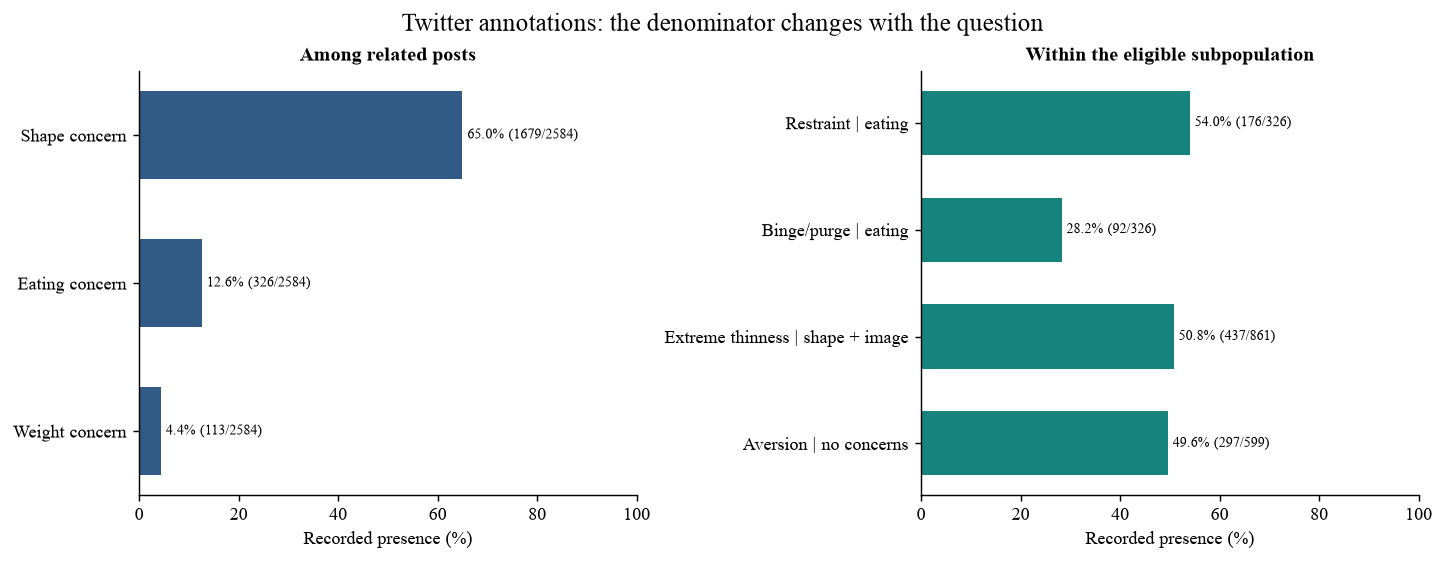

,annotation,yes n,eligible n,percent
0,Shape concern,1679,2584,65.0
1,Eating concern,326,2584,12.6
2,Weight concern,113,2584,4.4
3,Restraint | eating,176,326,54.0
4,Binge/purge | eating,92,326,28.2
5,Extreme thinness | shape + image,437,861,50.8
6,Aversion | no concerns,297,599,49.6


**Interpretation.** Shape concern is the most common of the three main concerns: 1,679/2,584 (65.0%), versus 326/2,584 (12.6%) for eating and 113/2,584 (4.4%) for weight. Among eating-concern posts, 176/326 (54.0%) record restraint. This supports retaining body image as a central topic, while treating food-related concerns as a smaller, explicitly defined subset. These are annotation frequencies in the selected corpus, not population illness rates.

In [16]:
# Summarize individual Twitter codes using their codebook-defined denominators.
def prevalence(frame, fields):
    rows = []
    for col, label in fields:
        n = int(frame[col].notna().sum())
        count = int((frame[col] == 1).sum())
        rows.append([label, count, n, 100 * count / n])
    return pd.DataFrame(rows, columns=['annotation', 'yes n', 'eligible n', 'percent'])
tw_main = prevalence(twitter, [('shape', 'Shape concern'),
                               ('eating', 'Eating concern'), ('weight', 'Weight concern')])
tw_nested = prevalence(twitter, [('restraint', 'Restraint | eating'),
 ('purge', 'Binge/purge | eating'), ('extreme', 'Extreme thinness | shape + image'),
 ('aversion', 'Aversion | no concerns')])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout='constrained')
for ax, table, color, title in zip(axes, [tw_main, tw_nested], [BLUE, TEAL],
 ['Among related posts', 'Within the eligible subpopulation']):
    ax.barh(table.annotation, table.percent, color=color, height=.6)
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('Recorded presence (%)')
    ax.set_title(title, fontsize=11)
    for i, row in table.iterrows():
        ax.text(row.percent + 1, i, f'{row.percent:.1f}% ({row["yes n"]}/{row["eligible n"]})',
                va='center', fontsize=8)
fig.suptitle('Twitter annotations: the denominator changes with the question', fontsize=14)
finish('01_twitter_themes')
display(pd.concat([tw_main, tw_nested], ignore_index=True).round(1))
display(Markdown('**Interpretation.** Shape concern is the most common of the three main '
 'concerns: 1,679/2,584 (65.0%), versus 326/2,584 (12.6%) for eating and '
 '113/2,584 (4.4%) for weight. Among eating-concern posts, 176/326 (54.0%) '
 'record restraint. This supports retaining body image as a central topic, while '
 'treating food-related concerns as a smaller, explicitly defined subset. These '
 'are annotation frequencies in the selected corpus, not population illness rates.'))

### 5.2 TikTok: recorded EDE categories and uncertainty from blank annotations
We count explicit category headers. The main percentages use 79 nonblank EDE annotations. For transparency, the table also gives the fraction of all 85 posts with a recorded category and an upper bound if all six blank annotations had that category. This is a missingness sensitivity description, not imputation or a confidence interval. No EDE category is compared to audio valence here.

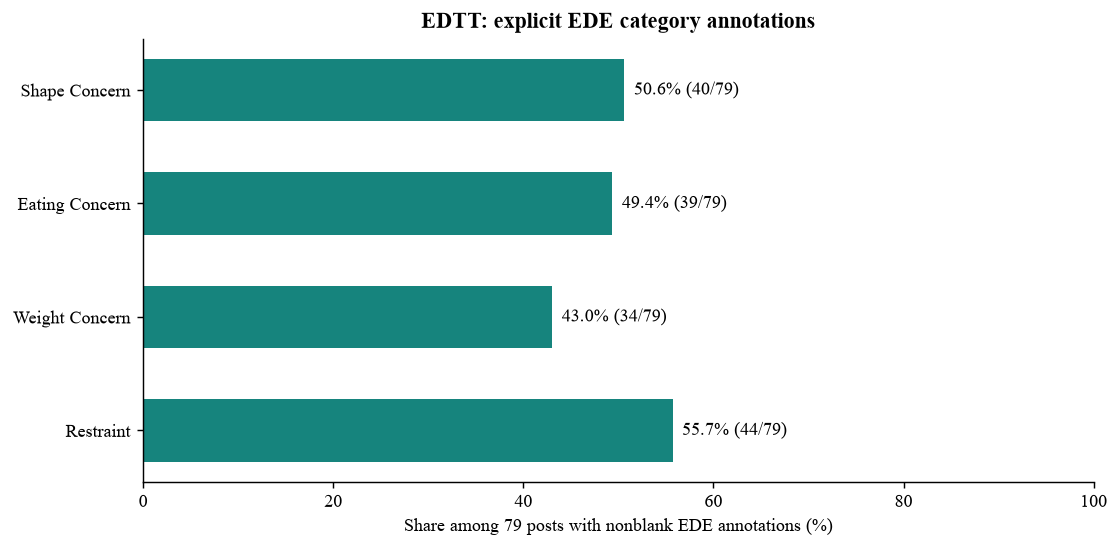

,annotation,yes n,eligible n,percent,all-row lower %,all-row upper %
0,Shape Concern,40,79,50.6,47.1,54.1
1,Eating Concern,39,79,49.4,45.9,52.9
2,Weight Concern,34,79,43.0,40.0,47.1
3,Restraint,44,79,55.7,51.8,58.8


**Interpretation.** Restraint is the most frequently recorded category (44/79, 55.7%). Categories can co-occur. Six blank source fields leave category status unresolved; the all-row bounds span 7.1 percentage points. We therefore keep missing flags and avoid interpreting a blank as evidence that a concern is absent.

In [17]:
# Describe EDE categories and expose the effect of the six blank source fields.
ede_table = prevalence(tiktok, [('ede_' + k, h) for k, h in ede_headers.items()])
ede_table['all-row lower %'] = 100 * ede_table['yes n'] / len(tiktok)
ede_table['all-row upper %'] = 100 * (ede_table['yes n'] + 6) / len(tiktok)
fig, ax = plt.subplots(figsize=(8.5, 4.1), layout='constrained')
ax.barh(ede_table.annotation, ede_table.percent, color=TEAL, height=.55)
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel('Share among 79 posts with nonblank EDE annotations (%)')
ax.set_title('EDTT: explicit EDE category annotations')
for i, row in ede_table.iterrows():
    ax.text(row.percent + 1, i, f'{row.percent:.1f}% ({row["yes n"]}/79)', va='center')
finish('02_edtt_ede')
display(ede_table.round(1))
lead = ede_table.sort_values('percent', ascending=False).iloc[0]
display(Markdown(f'**Interpretation.** {lead.annotation} is the most frequently recorded '
 f'category ({int(lead["yes n"])}/79, {lead.percent:.1f}%). Categories can co-occur. '
 'Six blank source fields leave category status unresolved; the all-row bounds span '
 f'{100*6/85:.1f} percentage points. We therefore keep missing flags and avoid '
 'interpreting a blank as evidence that a concern is absent.'))

### 5.3 TikTok: visual annotations by post format
This exploratory pairwise comparison asks whether visual features are recorded differently across videos and photo slideshows. It is separate from both planned analyses. Percentages are calculated within format, so unequal group sizes do not drive the chart. The connected points show descriptive differences only; their lines do not represent time or causation.

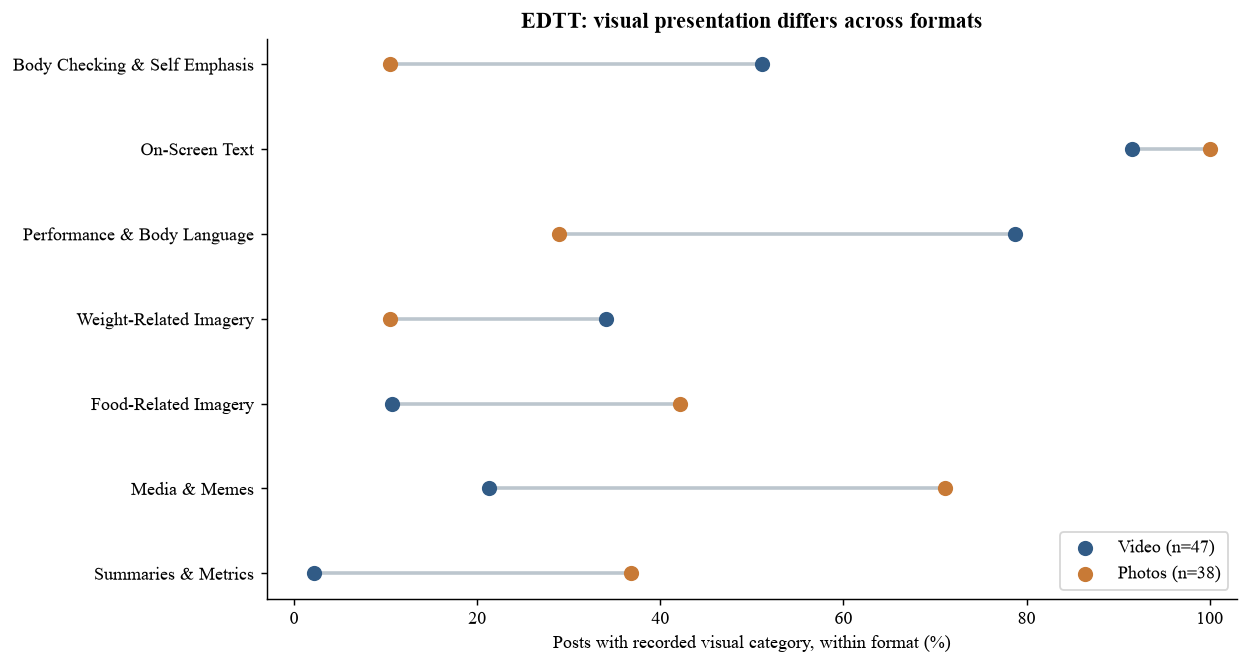

type,photos,video
visual category,,
Body Checking & Self Emphasis,10.5,51.1
On-Screen Text,100.0,91.5
Performance & Body Language,28.9,78.7
Weight-Related Imagery,10.5,34.0
Food-Related Imagery,42.1,10.6
Media & Memes,71.1,21.3
Summaries & Metrics,36.8,2.1


**Interpretation.** The sample contains 47 videos and 38 photo posts. The largest absolute format difference is for Performance & Body Language: -49.8 percentage points (photos minus videos). This suggests format is worth accounting for in the future audio model. It does not establish that changing format would change content.

In [18]:
# Grouped means: Lecture 11.
# Explore visual category presence by format without testing a hypothesis.
format_n = tiktok['type'].value_counts()
visual_rates = tiktok.groupby('type')[visual_cols].mean().T.astype(float) * 100
visual_rates.index = list(visual_headers.values())
fig, ax = plt.subplots(figsize=(9.5, 5), layout='constrained')
y = np.arange(len(visual_rates))
for i in range(len(visual_rates)):
    ax.plot([visual_rates.iloc[i]['video'], visual_rates.iloc[i]['photos']], [i, i],
            color='#BCC6CE', lw=2, zorder=1)
ax.scatter(visual_rates['video'], y, color=BLUE, s=55,
           label=f'Video (n={format_n["video"]})', zorder=2)
ax.scatter(visual_rates['photos'], y, color=ORANGE, s=55,
           label=f'Photos (n={format_n["photos"]})', zorder=2)
ax.set_yticks(y, visual_rates.index); ax.invert_yaxis(); ax.set_xlim(-3, 103)
ax.set_xlabel('Posts with recorded visual category, within format (%)')
ax.set_title('EDTT: visual presentation differs across formats')
ax.legend(loc='lower right'); finish('03_visual_format')
display(visual_rates.round(1).rename_axis('visual category'))
gap = (visual_rates['photos'] - visual_rates['video'])
label = gap.abs().idxmax()
display(Markdown(f'**Interpretation.** The sample contains {format_n["video"]} videos '
 f'and {format_n["photos"]} photo posts. The largest absolute format difference is '
 f'for {label}: {gap[label]:+.1f} percentage points (photos minus videos). '
 'This suggests format is worth accounting for in the future audio model. '
 'It does not establish that changing format would change content.'))

### 5.4 TikTok: distributions of audio measurements
Histograms describe numeric scale, spread, and shape before modeling. Every released row has these audio fields. The table includes medians and quartiles because averages alone can obscure clusters. The audio descriptors are not measures of audience response. We do not stratify valence by restraint, fit a regression, or compute an association test.

,count,mean,25%,50%,75%
audio_tempo_bpm,85.0,126.039,112.350,123.050,143.550
audio_valence,85.0,0.590,0.232,0.736,0.774
audio_arousal,85.0,0.342,0.303,0.332,0.385
harmonic_ratio,85.0,0.742,0.670,0.789,0.865


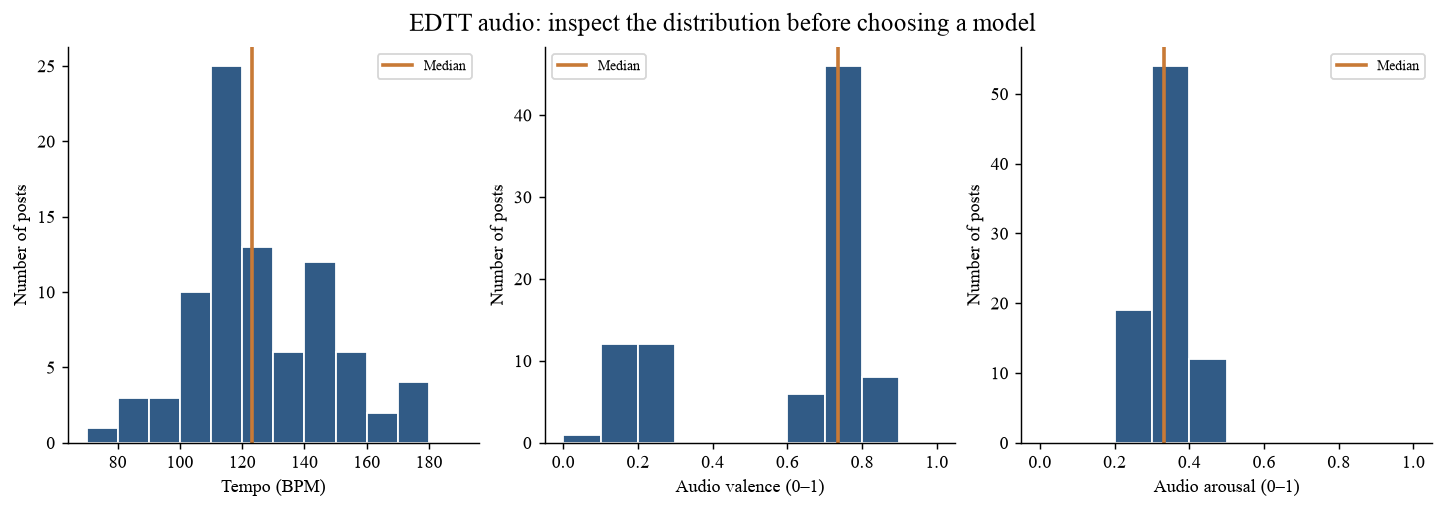

**Interpretation.** Median tempo is 123.05 BPM (IQR 112.35–143.55). Median valence is 0.736, while mean valence is 0.590; the histogram shows why one average is an incomplete summary. Arousal is concentrated in a narrow part of its 0–1 scale. These distributions motivate robust standard errors and cautious interpretation of the future mean-difference model, rather than treating audio scores as human emotions.

In [19]:
# Summary statistics: Lecture 3; pandas histograms: Lecture 4.
# Describe audio variables marginally; leave the proposed restraint model untouched.
audio_fields = ['audio_tempo_bpm', 'audio_valence', 'audio_arousal', 'harmonic_ratio']
audio_stats = tiktok[audio_fields].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
# Display a compact table for the PDF; the complete version is saved as a CSV.
audio_stats.to_csv(CLEAN / 'audio_summary.csv')
display(audio_stats[['count', 'mean', '25%', '50%', '75%']].round(3))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), layout='constrained')
for ax, field, label, bins in zip(axes,
 ['audio_tempo_bpm', 'audio_valence', 'audio_arousal'],
 ['Tempo (BPM)', 'Audio valence (0–1)', 'Audio arousal (0–1)'],
 [np.arange(70, 191, 10), np.linspace(0, 1, 11), np.linspace(0, 1, 11)]):
    tiktok[field].hist(ax=ax, bins=bins, color=BLUE, edgecolor='white', grid=False)
    ax.axvline(tiktok[field].median(), color=ORANGE, lw=2, label='Median')
    ax.set_xlabel(label); ax.set_ylabel('Number of posts'); ax.legend(fontsize=8)
fig.suptitle('EDTT audio: inspect the distribution before choosing a model', fontsize=14)
finish('04_audio_distributions')
display(Markdown(f'**Interpretation.** Median tempo is {tiktok.audio_tempo_bpm.median():.2f} BPM '
 f'(IQR {tiktok.audio_tempo_bpm.quantile(.25):.2f}–{tiktok.audio_tempo_bpm.quantile(.75):.2f}). '
 f'Median valence is {tiktok.audio_valence.median():.3f}, while mean valence is '
 f'{tiktok.audio_valence.mean():.3f}; the histogram shows why one average is an incomplete '
 'summary. Arousal is concentrated in a narrow part of its 0–1 scale. '
 'These distributions motivate robust standard errors and cautious interpretation '
 'of the future mean-difference model, rather than treating audio scores as human emotions.'))

### 5.5 What the EDA changes
We retain food and body-image content as the shared motivation but replace the original algorithm/engagement question with answerable within-source questions. The Twitter sample has a large shape-concern group and a smaller eating-concern group. EDTT contains both post formats and multimodal features, but only 79 records have interpretable EDE category status. This motivates one Twitter association model and one EDTT audio model, with prespecified missing-data rules.

The four figures were selected to show category frequencies, the impact of conditional denominators, one distinct exploratory pairwise relationship, and numeric distributions. No inferential test, fitted model, p-value, or preregistered predictor–outcome cross-tabulation has been run.

## 6. Questions for reviewers: Part 1
The main issues we want feedback on are whether our annotations measure the ideas in our question, how missing and inconsistent codes affect interpretation, and whether the two sources form a coherent project.

1. **Unresolved Twitter annotations:** Eleven posts have all three concern codes set to zero but `noconcern=0`. Is preserving them with a flag and checking the future model both with and without them preferable to excluding them now?
2. **Missing TikTok annotations:** Six EDTT rows have blank EDE text. Is treating their category status as unknown reasonable, and should we seek author clarification before deciding on any alternative coding?
3. **Different sampling and definitions:** Does presenting Twitter and TikTok as complementary case studies sufficiently connect the project, given that their percentages cannot identify platform differences and restraint has different coding rules?
4. **Construct validity:** Our original interest included food attitudes and recovery, but the files measure content annotations. Does the revised question stay close enough to our topic while avoiding unsupported claims about people or algorithm effects?
5. **EDA priorities:** Is the visual-feature comparison by format useful preparation for the planned audio model, or would you prioritize a different descriptive view without testing our preregistered associations?

## Part 2. Preregistration of future analyses
**Status and disclosure.** These statements specify future work after the Phase II data audit and EDA. They are not a claim that the data have never been viewed or that an external registry entry already exists. Source documentation, published aggregate results, row examples, a three-concern consistency check (including the 11 inconsistent rows), marginal distributions, and the format–visual comparison were inspected. The two proposed predictor–outcome associations below were not tabulated, tested, or modeled. Save a dated copy of these plans before performing them; document any later amendments and reasons.

**Reporting commitment.** The final report will include both analyses regardless of direction or statistical significance, along with sample sizes, exclusions, effect estimates, uncertainty, diagnostics, and limitations. The two primary tests form one family: use two-sided p-values and Holm correction at family-wise alpha 0.05 (smaller p compared with .025, then the other with .05 if the first passes). Report unadjusted and adjusted p-values. Statistical significance will not substitute for substantive interpretation.

## 7. Preregistration Statement 1: Co-occurring concerns on Twitter
**Hypothesis.** Among posts coded as ED/body-image related, shape-concern annotations are positively associated with eating-concern annotations. The rationale is that body-related and food-related themes can be expressed together; this is a content-level conjecture, not a claim about illness or causation. The design permits a negative or null result.

**Population and variables.** Use `twitter_related.csv` with `ed_about=1` (currently 2,584 posts). Outcome `eating` is 1 if eating concern was coded and 0 otherwise. Predictor `shape` is 1 if shape concern was coded and 0 otherwise. Use these original source codes without recoding restraint into the outcome. Exclude any row with a missing predictor/outcome, report the count, and do not impute. The current validation finds none. Keep all valid IDs, including the 11 flagged rows, because there is no evidence identifying an error in `shape` or `eating` specifically; do not deduplicate code patterns. Report a prespecified sensitivity refit excluding the 11 flagged rows, clearly secondary to the primary all-row model. The logical audit exposed their zero codes before this plan, which is disclosed rather than treated as unseen data.

**Model and estimand.** Fit a logistic regression:

`logit[P(eating = 1)] = beta_0 + beta_1 * shape`

The target is the within-sample odds ratio `exp(beta_1)` comparing shape-annotated with non-shape-annotated posts. Report both group probabilities as well, so an odds ratio is not mistaken for a risk ratio. The directional expectation is `beta_1 > 0`, but the primary test is two-sided `H0: beta_1 = 0`.

**Procedure, uncertainty, and diagnostics.** In the final phase only, report the 2-by-2 table, fit the model with statsmodels, and use the two-sided coefficient test with its 95% confidence interval. Report raw cell counts and flag any count below five. If any cell is zero or maximum likelihood fails due to separation/non-convergence, use a two-sided Fisher exact test as the prespecified fallback, report the empirical odds ratio (including zero/infinity if applicable), and obtain an exact conditional 95% interval with `scipy.stats.contingency.odds_ratio`. Do not add arbitrary pseudo-counts or search for a better-significance specification. If a variable has no variation, report that the association is not estimable.

**Interpretation and limits.** The model describes annotation co-occurrence in this selected corpus. It does not imply that body-image concerns cause eating concerns. Shared annotation practices, repeated creators, and retweets could affect the association and precision. Without creator IDs, independent-row standard errors may be too small; acknowledge this rather than claiming population generalizability. We do not add `noconcern`, which is determined by the concerns, as a control.

**What will be shown later:** counts, group probabilities, odds ratio and interval, test result, any fallback, and a short explanation even if the estimate contradicts the hypothesis.

## 8. Preregistration Statement 2: Restraint annotations and audio valence in EDTT
**Hypothesis.** Posts with a recorded restraint category have lower mean audio valence than posts without that category, conditional on format. This is a tentative hypothesis about the musical framing of food restriction. The link between semantic content and musical tone is uncertain; ironic or upbeat accompaniment could produce the opposite pattern. No association result is being assumed.

**Population and variables.** Use EDTT rows with a nonblank `ede_subscale_items` field and valid valence and format (currently 79 eligible rows). Outcome is `audio_valence` on its released 0–1 scale. Predictor `ede_restraint` is 1 when the explicit Restraint header appears and 0 when the nonblank field lacks it. `photos` is an indicator for `type='photos'`; video is the reference. Exclude blank EDE fields from the primary analysis and report six currently excluded rows. Do not treat the diagnostic field as a clinical outcome, remove outliers, or transform valence after seeing the coefficient.

**Model and estimand.** Fit ordinary least squares:

`audio_valence = beta_0 + beta_1 * ede_restraint + beta_2 * photos + error`

The target is the adjusted mean difference in valence units, `beta_1`. The expectation is `beta_1 < 0`, with a two-sided primary test `H0: beta_1 = 0`. Format is specified in advance because audiovisual construction may differ across formats. This model meets the requirement for a model relating variables to the research question; it does not make a causal adjustment claim.

**Procedure and uncertainty.** Fit with statsmodels and HC3 heteroskedasticity-robust standard errors using its t-based inference option (`use_t=True`). Report coefficient, 95% interval, primary p-value, eligible group sizes, adjusted predictions by restraint and format, and R-squared. Inspect residual-versus-fitted values, leverage, and Cook's distance. Flag Cook's distance above `4/n` but retain those rows in the primary model. Report predictions outside 0–1 if they occur. If the design matrix is rank deficient or restraint has no variation, report non-estimability rather than choosing a different predictor.

**Prespecified sensitivity, not a replacement primary test.** Refit the same model twice including the six blank-EDE rows: once coding their restraint status as 0 and once as 1. Report the resulting coefficients and intervals as extreme-assignment scenarios, not as sharp bounds or as evidence that missingness is random. Keep the original complete-annotation model as primary regardless of significance. These sensitivities are not additional confirmatory claims.

**Interpretation and limits.** A difference in heuristic musical valence is not evidence of a difference in viewers' emotions, symptoms, or engagement. HC3 addresses unequal residual variance, not dependence from reused audio or creators. The purposive sample and modest size restrict generalization and power. Diagnostics are reported transparently, not used to select a more favorable hypothesis.

**What will be shown later:** sample flow, the regression table, an adjusted-prediction plot, diagnostics, sensitivity estimates, and interpretation even when the interval includes zero.

## Appendix A. Data cleaning appendix and reproducibility
**Files.** data/raw/ contains unchanged source downloads and the checksum manifest. `data/intermediate/` contains validated/normalized snapshots. `data/processed/` contains analysis tables and audits. `figures/` contains the four charts. The download bundle includes these files, the executed notebook, its HTML view, and the combined PDF. In GitHub, the notebook is in notebooks/ and the report is in `reports/phase2/`.

**Re-run.** Extract the full ZIP, install the packages in `requirements.txt` in a Python environment, open this notebook from the extracted directory, select that environment's kernel, and choose Restart Kernel and Run All. A complete local bundle runs offline. A notebook opened alone in Colab needs internet access on its first run to restore the saved inputs from GitHub. Processed files and figures are overwritten reproducibly. All code cells should finish without errors. No proposed inferential analyses are implemented here.

**Hosted raw inputs.** The [verified GitHub raw-data folder](https://github.com/AnyaChoudhary/info2950-fall2026-project/tree/905e574351e821300dc5b199747216a3bd630e1b/data/raw) contains both original CSVs, the Twitter codebook and filtering appendix, and `manifest.json`. These are the exact bytes used in this execution. The publisher links in Section 2 provide independent access to the original releases.

**Cleaning trace.** Section 2.2 verifies the four original files; Section 2.3 validates Twitter codes and their conditional universes, saves all 3,000 rows, retains 2,584 related posts, and flags 11 logical inconsistencies; Section 2.4 normalizes all 85 EDTT rows and derives 11 category indicators plus a count while preserving six unknown EDE annotations; Section 2.5 saves row-flow and eligibility audits. Sections 5.1–5.4 generate the displayed summaries and figures from those analysis-ready files. Every code cell has an executed output or visible saved-file result, and the proposed inference remains unperformed.

## Appendix B. References
1. Cavazos-Rehg, P. A., et al. (2019). “I just want to be skinny.”: A content analysis of tweets expressing eating disorder symptoms. *PLOS ONE*, 14(1), e0207506. https://doi.org/10.1371/journal.pone.0207506. S1 Dataset, S1 Codebook, and S1 Appendix are bundled unchanged.
2. Shaveet, E., Viranda, T., & Choudhury, T. (2026). *EDTT Dataset*, version 2. Zenodo. https://doi.org/10.5281/zenodo.19749827. Public dictionary: https://edenshaveet.github.io/EDTT/.
3. Project repository: https://github.com/AnyaChoudhary/info2950-fall2026-project. Inspection snapshot recorded in Section 2.
4. INFO 2950, Fall 2026. *Phase II: Exploratory analysis and hypotheses*. User-supplied course rubric, read in full. Its datasheet-style prompts guide Sections 3 and 4.

## 9. Questions for reviewers: Part 2
For the final phase, we want feedback on whether our proposed models answer meaningful content questions and whether their uncertainty and sensitivity plans are adequate for these samples.

1. **Model choice:** Is logistic regression for Twitter concern co-occurrence appropriate at this course level, with Fisher's exact test as the prespecified fallback for zero cells or separation?
2. **Audio interpretation:** Is musical valence a meaningful way to study content framing, provided we do not interpret it as a creator's or viewer's emotional state? Should the hypothesis be reframed before any model is fit?
3. **Bounded outcome and small sample:** Is a mean-difference model with HC3 uncertainty appropriate for valence among 79 EDTT posts? If a different method is preferable, what estimand should a dated amendment preserve?
4. **Missingness sensitivity:** Are assigning all six unknown restraint labels to zero and then to one useful scenario checks, given that these are not sharp bounds? Should source-author clarification take priority?
5. **Dependence and uncertainty:** Without reliable creator or repeated-audio identifiers, how prominently should we qualify the independence assumption, and should the report emphasize descriptive effect estimates over significance?
6. **Scope and coherence:** Do the two within-source analyses adequately address one project about food and body-image content, or should we narrow the final report while still presenting both preregistered analyses regardless of results?
